# 교과서에서 전처리·탐색한 `weather2023.xlsx`를 이용하여  
기온(temp), 풍속(wind), 습도(humi), 전운량(cloud)으로  
합계 일조시간(sunshine)을 예측하는 선형회귀 모델을 만드는 실습이다.

<탐구질문> 오늘의 기온, 풍속,습도, 전운량을 알면 일조시간을 예측할 수 있을까?

STEP 1. 라이브러리 불러오기와 데이터 확인, 데이터 전처리


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

weather=pd.read_excel('weather2023.xlsx', index_col='date')
weather.drop(['rain','location','loc_name'],axis=1,inplace=True)
weather.head()

,temp,wind,humi,sunshine,cloud
date,,,,,
2023-01-01,-0.2,2.7,55.0,9.0,1.3
2023-01-02,-4.5,2.5,46.0,9.1,0.0
2023-01-03,-5.0,1.8,49.0,9.1,0.0
2023-01-04,-1.8,1.9,51.0,8.7,1.9
2023-01-05,-1.6,1.6,58.1,4.7,3.6


STEP 2-1. 특성변수 후보와 목표변수의 관계 시각화하기(1)

STEP 2-2. 특성변수 후보와 목표변수의 관계 시각화하기(2)


STEP3. 입력 데이터 X와 정답 y 정하기

In [2]:
X=weather[['temp','wind','humi','cloud']]
y=weather['sunshine']
print(X.head())
print(y.head())

            temp  wind  humi  cloud
date                               
2023-01-01  -0.2   2.7  55.0    1.3
2023-01-02  -4.5   2.5  46.0    0.0
2023-01-03  -5.0   1.8  49.0    0.0
2023-01-04  -1.8   1.9  51.0    1.9
2023-01-05  -1.6   1.6  58.1    3.6
date
2023-01-01    9.0
2023-01-02    9.1
2023-01-03    9.1
2023-01-04    8.7
2023-01-05    4.7
Name: sunshine, dtype: float64


STEP4. 훈련데이터와 테스트테이터로 분리하기

In [3]:
%pip install scikit-learn

In [6]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2, random_state=42
)
print('훈련 데이터:',X_train.shape)
print('테스트 데이터:',X_test.shape)

훈련 데이터: (144, 4)
테스트 데이터: (37, 4)


STEP5. 모델1: 선형회귀 모델 학습하기

In [8]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train);

STEP6. 모델1: 테스트 데이터 예측하기

In [9]:
pred=model.predict(X_test)
result=pd.DataFrame({
    'original_index':y_test.index,
    'actual':y_test.values,
    'predicted':pred
})

print(result.head(10))

  original_index  actual  predicted
0     2023-01-20     8.7  10.220608
1     2023-02-12     2.0   2.696020
2     2023-06-03    13.3  10.724790
3     2023-03-20    10.0   8.865658
4     2023-05-26    10.7   5.592091
5     2023-01-16     8.8   6.580402
6     2023-01-25     9.4   8.029100
7     2023-03-10     9.6  11.635115
8     2023-04-24     7.8   7.349061
9     2023-04-29     0.8   0.118703


STEP7. 모델1: 성능 평가하기

In [10]:
from sklearn.metrics import mean_absolute_error, r2_score
mae=mean_absolute_error(y_test,pred)
r2=r2_score(y_test,pred)
print('MAE:',mae)
print('R2:',r2)

MAE: 1.4872732719755142
R2: 0.773778772233753


STEP8. 모델2: 랜덤포레스트 학습, 예측, 성능평가 (STEP5~7 모델명만 바꿔서 학습)

STEP9. 모델1과 모델2: 성능비교 

In [ ]:
X1=weather[['cloud']]
y=weather['sunshine']
X1_train,X1_test,y1_train,y1_test=train_test_split(
    X1,y,test_size=0.2, random_state=42
)

model1=LinearRegression()
model1.fit(X1_train, y1_train)
pred1=model1.predict(X1_test)

mae1=mean_absolute_error(y1_test,pred1)
r21=r2_score(y1_test,pred1)

print('cloud만 사용한 MAE:', mae1)
print('cloud만 사용한 R² :', r21)
print()
print('4개 특성 사용 MAE:', mae)
print('4개 특성 사용 R² :', r2)


cloud만 사용한 MAE: 1.9835570533591926
cloud만 사용한 R² : 0.6335007834575183

4개 특성 사용 MAE: 1.4872732719755142
4개 특성 사용 R² : 0.773778772233753


STEP10. 성능 평가 결과로 모델 선정, 실제값과 예측값 시각화하기

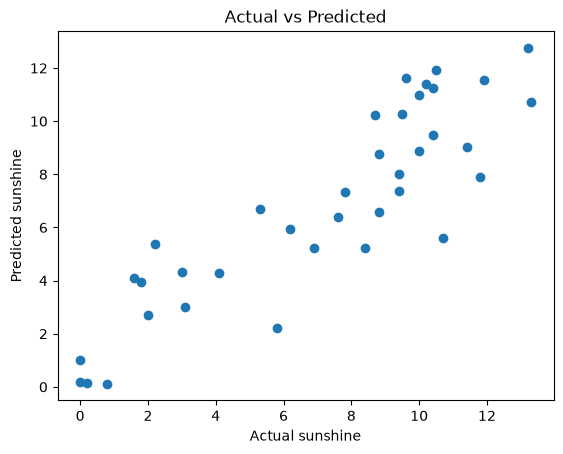

In [ ]:
plt.scatter(y_test,pred)
plt.xlabel('Actual sunshine')
plt.ylabel('Predicted sunshine')
plt.title('Actual vs Predicted')
plt.show()

STEP 11. 새로운 날씨 데이터 예측하기

 - X값 중 하나 이상을 바꾸어 새로운 날씨의 일조 시간 예측

In [ ]:
new_weather=pd.DataFrame(
    {'temp':[20.0],
     'wind':[2.5],
     'humi':[60.0],
     'cloud':[4.0]
    })
new_pred=model.predict(new_weather)
print('예측 일조시간:',new_pred[0])

예측 일조시간: 8.46728864137906


<회귀 모델 성능지표 해석>

MAE: 작을수록 좋음 (실제값과 예측값이 평균적으로 얼마나 차이 나는지?)

R²: 1에 가까울수록 좋음 (모델이 실제 데이터의 변화를 얼마나 잘 설명하는지?)

STEP10. 랜덤포레스트 회귀와 비교